### Setup

These cells are copied unchanged from Section 1 of `exam2.ipynb`: the imports, the Black–Scholes functions and sample data of §1.4, and the simulation code of §1.6–§1.8. Run them before the Results below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad
from scipy.stats import binom


In [2]:
def _d1_d2(S, K, T, r, sigma):
    # d1 and d2 as in §1.4 (Lecture 1, p.43). np.log / np.sqrt rather than math.*, so that
    # S, sigma, T and r may be arrays when the data are varied in the parameter studies.
    sqrtT = np.sqrt(T)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
    return d1, d1 - sigma * sqrtT


def bs_price(S, K, T, r, sigma, kind='call'):
    '''
    S: spot price
    K: strike price
    T: time to expiry T - t (in years)
    r: risk-free interest rate (annualized)
    sigma: volatility (annualized)
    kind: 'call' or 'put'
    '''
    d1, d2 = _d1_d2(S, K, T, r, sigma)
    disc_K = K * np.exp(-r * T)                    # present value of the strike
    if kind == 'call':
        return S * norm.cdf(d1) - disc_K * norm.cdf(d2)
    if kind == 'put':
        return disc_K * norm.cdf(-d2) - S * norm.cdf(-d1)
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


def bs_greeks(S, K, T, r, sigma, kind='call'):
    '''
    Analytic Black-Scholes greeks, the benchmark for the Monte Carlo greeks.
    Returns dict(delta, gamma, vega, theta, rho), each per unit change: vega per 1.00 of sigma,
    rho per 1.00 of r, theta per year. Theta is dV/dt, so it is negative for a call.
    '''
    d1, d2 = _d1_d2(S, K, T, r, sigma)
    sqrtT, disc_K, pdf = np.sqrt(T), K * np.exp(-r * T), norm.pdf(d1)
    gamma = pdf / (S * sigma * sqrtT)              # same for call and put
    vega = S * sqrtT * pdf                         # same for call and put
    decay = -sigma * S * pdf / (2 * sqrtT)         # theta term shared by call and put
    if kind == 'call':
        return dict(delta=norm.cdf(d1), gamma=gamma, vega=vega,
                    theta=decay - r * disc_K * norm.cdf(d2),
                    rho=T * disc_K * norm.cdf(d2))
    if kind == 'put':
        return dict(delta=norm.cdf(d1) - 1, gamma=gamma, vega=vega,
                    theta=decay + r * disc_K * norm.cdf(-d2),
                    rho=-T * disc_K * norm.cdf(-d2))
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


def payoff(ST, K, kind='call'):
    # Vanilla payoff at expiry: max(S_T - K, 0) for a call, max(K - S_T, 0) for a put.
    if kind == 'call':
        return np.maximum(ST - K, 0.0)
    if kind == 'put':
        return np.maximum(K - ST, 0.0)
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


In [3]:
# Sample data from the exam brief (K = strike, T = time to expiry T - t)
S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.20

d1, d2 = _d1_d2(S0, K, T, r, sigma)
C, P = bs_price(S0, K, T, r, sigma, 'call'), bs_price(S0, K, T, r, sigma, 'put')


def p_tilde(S_prime, S, T, r, sigma):
    # Risk-neutral lognormal transition density of S_T = S_prime, given S_t = S (§1.3)
    bracket = np.log(S / S_prime) + (r - 0.5 * sigma**2) * T
    return np.exp(-bracket**2 / (2 * sigma**2 * T)) / (sigma * S_prime * np.sqrt(2 * np.pi * T))


# For each option: the payoff, and the range of S' where it is non-zero (§1.4)
contracts = {'call': (lambda s: s - K, K, np.inf),
             'put':  (lambda s: K - s, 0.0, K)}

rows = {}
for kind, (pay, lower, upper) in contracts.items():
    expected, _ = quad(lambda s: p_tilde(s, S0, T, r, sigma) * pay(s), lower, upper)
    rows[kind] = {
        'E^Q[payoff], integral': expected,
        'price, discounted integral': np.exp(-r * T) * expected,
        'price, closed form': bs_price(S0, K, T, r, sigma, kind),
    }

benchmark = pd.DataFrame(rows).T
benchmark['difference'] = benchmark['price, discounted integral'] - benchmark['price, closed form']

print(f"Black-Scholes closed form:   call C = {C:.4f}   put P = {P:.4f}\n")
print(f"d1 = {d1:.4f}   d2 = {d2:.4f}   N(d1) = {norm.cdf(d1):.5f}   N(d2) = {norm.cdf(d2):.5f}\n")
print(benchmark.to_string(float_format=lambda x: f'{x:.6f}' if abs(x) > 1e-4 else f'{x:.1e}'))
print(f"\nPut-call parity:  C - P = {C - P:.6f}   S - K e^(-rT) = {S0 - K * np.exp(-r * T):.6f}")


Black-Scholes closed form:   call C = 10.4506   put P = 5.5735

d1 = 0.3500   d2 = 0.1500   N(d1) = 0.63683   N(d2) = 0.55962

      E^Q[payoff], integral  price, discounted integral  price, closed form  difference
call              10.986396                   10.450584           10.450584     3.6e-15
put                5.859287                    5.573526            5.573526    -1.8e-15

Put-call parity:  C - P = 4.877058   S - K e^(-rT) = 4.877058


In [4]:
SEED = 1995                                        

#K, S0, r, sigma, T defined already in sample data above 

# payoff(ST, K, kind) is defined with the Black-Scholes functions in §1.4


def simulate_terminal_exact(S0, r, sigma, T, n_paths, rng): #GBM assumptions one step simulation to maturity #S_T = S_0 · exp((r − σ²/2)T + σ√T · Z),Z ~ N(0,1)
    phi = rng.standard_normal(n_paths)
    return S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * phi)


def mc_price_from_ST(ST, K, T, r, kind='call'): #MC payoff determined from payoff across average of terminal stock prices, discounted to present value
                                                 #standard error equal to sample standard deviation from the mean / sqrt(N)
    Y = np.exp(-r * T) * payoff(ST, K, kind)
    return Y.mean(), Y.std(ddof=1) / np.sqrt(Y.size)


In [5]:
def euler_paths(S0, r, sigma, T, Z):
    # Euler-Maruyama (§1.8): S_{n+1} = S_n + r S_n dt + sigma S_n dW_n.
    # Z holds the standard normal draws: one row per path, one column per time step.
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    dW = np.sqrt(dt) * Z                                  # Brownian increments, variance dt
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    for n in range(n_steps):                              # loop over time; every path moves at once
        S[:, n + 1] = S[:, n] + r * S[:, n] * dt + sigma * S[:, n] * dW[:, n]
    return S


In [6]:
def milstein_paths(S0, r, sigma, T, Z):
    # Milstein (§1.8): the Euler step plus the Ito-Taylor term 1/2 b b' (dW^2 - dt),
    # which for geometric Brownian motion (b = sigma S, b' = sigma) is 1/2 sigma^2 S_n (dW_n^2 - dt).
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    dW = np.sqrt(dt) * Z
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    for n in range(n_steps):
        Sn, dWn = S[:, n], dW[:, n]
        S[:, n + 1] = Sn + r * Sn * dt + sigma * Sn * dWn + 0.5 * sigma**2 * Sn * (dWn**2 - dt)
    return S


In [7]:
def exact_paths(S0, r, sigma, T, Z):
    # Exact solution of geometric Brownian motion (§1.8): ln S moves by (r - sigma^2/2) dt + sigma dW
    # on every step, whatever the step size, so add up the log-steps along each path and exponentiate.
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    log_paths = np.cumsum((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z, axis=1)
    return np.hstack([np.full((n_paths, 1), S0), S0 * np.exp(log_paths)])


In [8]:
SCHEMES = {'euler': euler_paths, 'milstein': milstein_paths, 'exact': exact_paths}


def simulate_paths(S0, r, sigma, T, n_steps, n_paths, rng, scheme='euler', Z=None):
    # Single entry point for the pricing code: draw the normals from the seeded generator
    # (unless Z is supplied, e.g. -Z for antithetic paths), then run the chosen scheme.
    # Returns an array of shape (n_paths, n_steps + 1); column 0 is S0.
    if scheme not in SCHEMES:
        raise ValueError(f"scheme must be one of {list(SCHEMES)}, got {scheme!r}")
    if Z is None:
        Z = rng.standard_normal((n_paths, n_steps))
    return SCHEMES[scheme](S0, r, sigma, T, Z)


#### 2.5.1 Stochastic volatility: how the schemes cope when $\sigma$ is random

So far $\sigma$ has been a fixed number. Lecture 7 (p.6) leaves open the question "What if it's random?". Here we let
it be random and repeat the scheme comparison of §2.2. Under geometric Brownian motion (GBM) the exact scheme of §1.8
has no discretisation error. With random volatility none of our schemes is exact, and this is the case for which §1.5
reserves Euler–Maruyama and Milstein.

We use the Heston model. The variance $v$ (volatility squared) gets its own equation. It is pulled back towards
a long-run level $\theta$ at speed $\kappa$, so it cannot drift off for ever. It is shaken by its own Brownian motion,
scaled by $\xi$, the volatility of variance. Our first comparison sets the correlation of the two Brownian motions to $\rho=-0.7$, so
volatility tends to rise when the stock falls. We then vary this correlation separately. Under $\mathbb{Q}$:

$$
dS = rS\,dt + \sqrt{v}\,S\,dX_1, \qquad
dv = \kappa(\theta - v)\,dt + \xi\sqrt{v}\,dX_2, \qquad
\mathrm{Corr}(dX_1, dX_2) = \rho .
$$

We keep $S_0$, $K$, $T$ and $r$ at the sample values and set $v_0=\theta=0.04$.
Expected variance then remains 0.04, matching the variance of the constant 20% volatility benchmark;
expected volatility itself need not equal 20%. With $\xi=0$, the variance stays constant and we recover GBM.

**The first input varied here is $\xi$, the volatility of variance.** The two cases use $\xi=0.3$ and $0.7$.
As introduced in §1.11, the Feller condition compares the pull away from zero with the size of variance
shocks. At the chosen $\kappa$ and $\theta$, $2\kappa\theta=0.16$: the condition holds when $\xi=0.3$
($\xi^2=0.09$) and fails when $\xi=0.7$ ($\xi^2=0.49$).

| Table/figure label | Variance fluctuations | $\kappa$ | $\theta=v_0$ | $\xi$ | $\rho$ | $2\kappa\theta/\xi^2$ |
|---|---|---|---|---|---|---|
| Feller satisfied | Lower | 2 | 0.04 | 0.3 | −0.7 | 1.78 |
| Feller violated | Higher | 2 | 0.04 | 0.7 | −0.7 | 0.33 |

In the second case, zero is attainable in the continuous variance process, making the numerical treatment
near zero especially relevant. The continuous process remains non-negative in both cases. Discrete
approximations can produce negative variance even in the first case; satisfying the Feller condition
does not guarantee that a numerical scheme preserves positivity.

**What we measure, and against what.**

- **Benchmark (Table 2.5.1a).** Heston's semi-closed form, $C = S_0P_1 - Ke^{-r(T-t)}P_2$, is the counterpart of the
  Black–Scholes formula of §1.4: $P_2 = \mathbb{Q}(S_T > K)$ plays the role of $N(d_2)$. $P_1$ and $P_2$ come from
  integrating the characteristic function of $\ln S_T$ numerically. Before we rely on it, we check it against
  Black–Scholes as $\xi \to 0$, against a second, independent pricing formula, and against a fine-step Monte Carlo price.
- **Weak error**, the bias of the call price, against $\delta t$ for each scheme, under GBM and both Heston sets:
  Table 2.5.1b and Figure 2.5.1a. The table retains monthly and daily values; the figure shows the full ladder.
- **Strong error relative to a reference**, how far each terminal price lands from the exact GBM
  solution or the fine-grid Heston approximation driven by the same Brownian path, and the share of steps on
  which the variance goes negative: Table 2.5.1c and Figure 2.5.1b.
- **The smile.** We compare implied volatility across strikes with the flat 20% Black–Scholes
  benchmark. Implied volatility is the Black–Scholes volatility that reproduces a given Heston price
  (Lecture 7, pp.61–63): Figure 2.5.1c. The left panel keeps the original $\xi$ comparison. The right
  panel holds $\xi=0.3$ and all other inputs fixed, changing only $\rho$ to $-0.7$, $0$ and $+0.7$.
  The Feller condition therefore remains satisfied. This asks how much the downward slope depends on
  our negative-correlation choice. Positive correlation is included as a comparison, not a market calibration.
  Selected Monte Carlo points use the log scheme, common random numbers and 100,000 paths on 504 steps;
  paired 252-step paths provide a check on time-step sensitivity. The intervals show sampling uncertainty only.

**What §1.8 predicts.** Under GBM: Euler strong order ½ and weak order 1, Milstein strong and weak order 1, and no
error for the exact scheme. For the Heston approximation used here, omitting part of the two-noise interaction can remove
Milstein's order-1 advantage. The stock's volatility now
depends on a second Brownian motion, and a full Milstein step needs the iterated integral
$\int\!\!\int dX_2\,dX_1$, which the increments $\delta X_1, \delta X_2$ do not determine (Kloeden and Platen,
1992). The square-root coefficient is not differentiable at zero; when that boundary is attainable,
the regularity assumptions behind the usual convergence orders need particular care.


In [9]:
# Heston stochastic volatility under Q (§2.5.1):
#   dS = r S dt + sqrt(v) S dX1,   dv = kappa (theta - v) dt + xi sqrt(v) dX2,   Corr(dX1, dX2) = rho.
# Both sets start at v0 = theta = 0.04, so E[v_t] = 0.04 on every date (the variance of the 20% volatility benchmark);
# they differ only in the volatility of variance xi, which decides whether the Feller condition holds.
sv_params = {
    'Feller satisfied': dict(v0=0.04, kappa=2.0, theta=0.04, xi=0.3, rho=-0.7),
    'Feller violated':  dict(v0=0.04, kappa=2.0, theta=0.04, xi=0.7, rho=-0.7),
}


def heston_cf(u, S0, r, T, p, form='trap'):
    # Characteristic function E^Q[exp(i u ln S_T)] of the Heston model, for real or complex u.
    # form='trap': the numerically stable rearrangement of the formula, continuous in u at every maturity: np.sqrt gives d
    # with positive real part, so |g| < 1 and e^{-dT} decays, and the complex log never jumps between branches;
    # form='original': the original form of the characteristic function, used only as an independent check.
    kappa, theta, xi, rho, v0 = p['kappa'], p['theta'], p['xi'], p['rho'], p['v0']
    b = kappa - rho * xi * 1j * u
    d = np.sqrt(b**2 + xi**2 * (1j * u + u**2))
    if form == 'trap':
        g = (b - d) / (b + d)
        C = kappa * theta / xi**2 * ((b - d) * T - 2 * np.log((1 - g * np.exp(-d * T)) / (1 - g)))
        D = (b - d) / xi**2 * (1 - np.exp(-d * T)) / (1 - g * np.exp(-d * T))
    else:
        g = (b + d) / (b - d)
        C = kappa * theta / xi**2 * ((b + d) * T - 2 * np.log((1 - g * np.exp(d * T)) / (1 - g)))
        D = (b + d) / xi**2 * (1 - np.exp(d * T)) / (1 - g * np.exp(d * T))
    return np.exp(1j * u * (np.log(S0) + r * T) + C + D * v0)


def heston_price(S0, K, T, r, p, kind='call'):
    # Semi-closed-form Heston price C = S0 P1 - K e^{-rT} P2, the counterpart of S N(d1) - K e^{-rT} N(d2) in §1.4:
    # P2 = Q(S_T > K), and P1 is the same probability under the stock measure, both by Fourier inversion of the
    # characteristic function. The integrands are negligible beyond u = 200 here, so the integrals stop there.
    cf = lambda u: heston_cf(u, S0, r, T, p)
    forward = S0 * np.exp(r * T)                                    # E^Q[S_T], equal to cf(-i)
    P1 = 0.5 + quad(lambda u: (np.exp(-1j * u * np.log(K)) * cf(u - 1j) / (1j * u * forward)).real,
                    0, 200, limit=200)[0] / np.pi
    P2 = 0.5 + quad(lambda u: (np.exp(-1j * u * np.log(K)) * cf(u) / (1j * u)).real,
                    0, 200, limit=200)[0] / np.pi
    call = S0 * P1 - K * np.exp(-r * T) * P2
    if kind == 'call':
        return call
    if kind == 'put':
        return call - S0 + K * np.exp(-r * T)                       # put-call parity
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


def heston_price_single_integral(S0, K, T, r, p):
    # Independent check on heston_price: a second pricing formula, written as a single integral
    #   C = S0 - sqrt(S0 K) e^{-rT/2} / pi * integral_0^inf Re[e^{iuk} f(u - i/2)] / (u^2 + 1/4) du,
    # with k = ln(S0/K) + rT and f the characteristic function of ln(S_T/S0) - rT, in Heston's original form.
    k = np.log(S0 / K) + r * T
    f = lambda u: heston_cf(u, S0, r, T, p, form='original') * np.exp(-1j * u * (np.log(S0) + r * T))
    integral = quad(lambda u: (np.exp(1j * u * k) * f(u - 0.5j)).real / (u**2 + 0.25), 0, 200, limit=200)[0]
    return S0 - np.sqrt(S0 * K) * np.exp(-r * T / 2) / np.pi * integral


**The schemes under Heston.** Each scheme of §1.8 is applied to the pair $(S, v)$. The two Brownian increments are
built from independent standard normal draws $\phi, \phi'$ so that they have correlation $\rho$. Only the positive part
of the variance, $v_n^+ = \max(v_n, 0)$, is ever used inside the coefficients.

- **Euler** steps $S$ as in §1.8 and $v$ with the *full truncation* fix of Lord, Koekkoek and van Dijk (2010): $v$ may
  go negative, but only its positive part drives the next step. They found it the most accurate of the biased
  schemes they compared.
- **Milstein** adds the $\tfrac12 b\,b'$ correction of §1.8 to each equation, and a cross term to the $S$ step because
  $v$ moves inside $\sqrt{v}\,S$. The Lévy-area part of that cross term is dropped. It describes the interaction of the
  two Brownian motions within the step, which their endpoint increments alone do not determine. $v$ is floored at zero after
  each step.
- **Milstein-FT** (`milstein_ft`) is a diagnostic variant: Milstein's step for $S$ with Euler's step for $v$. This changes both the variance update and its treatment near zero, so the comparison
  does not isolate the effect of flooring alone.
- **log** is the exact step of §1.8 for $S$ with the variance frozen over the step, and Euler's step for $v$. With
  $\xi = 0$ it *is* the exact scheme of §1.8. Exact simulation of Heston (Broadie and Kaya, 2006) is far more
  involved and is beyond the present study.

In symbols, the increments, the three steps for $S$ and the two steps for $v$ are

$$
\begin{aligned}
&\delta X_1 = \sqrt{\delta t}\,\phi, \qquad \delta X_2 = \rho\,\delta X_1 + \sqrt{1-\rho^2}\,\sqrt{\delta t}\,\phi', \\
\text{Euler:}\quad &\hat S_{n+1} = \hat S_n + r\hat S_n\,\delta t + \sqrt{v_n^+}\,\hat S_n\,\delta X_1, \\
\text{Milstein:}\quad &\hat S_{n+1} = \hat S_n + r\hat S_n\,\delta t + \sqrt{v_n^+}\,\hat S_n\,\delta X_1
  + \tfrac12 v_n^+\hat S_n\left(\delta X_1^2 - \delta t\right) + \tfrac14\xi\hat S_n\left(\delta X_1\delta X_2 - \rho\,\delta t\right), \\
\text{log:}\quad &\ln \hat S_{n+1} = \ln \hat S_n + \left(r - \tfrac12 v_n^+\right)\delta t + \sqrt{v_n^+}\,\delta X_1, \\
\text{full truncation } v:\quad &v_{n+1} = v_n + \kappa(\theta - v_n^+)\,\delta t + \xi\sqrt{v_n^+}\,\delta X_2, \\
\text{Milstein } v:\quad &v_{n+1} = \max\!\left(v_n^+ + \kappa(\theta - v_n^+)\,\delta t + \xi\sqrt{v_n^+}\,\delta X_2
  + \tfrac14\xi^2\left(\delta X_2^2 - \delta t\right),\; 0\right).
\end{aligned}
$$

**Measuring a bias smaller than the noise: common random numbers.** Many of the biases in Table 2.5.1b are smaller
than the standard error of a price from $N = 200{,}000$ paths, which is 0.02 to 0.03. Comparing two independent
prices would not show them. So every path is first simulated on a fine grid of $n_{\text{ref}} = 3{,}276$ steps (13
per trading day). The same path on a coarse grid of $n$ steps is built by adding up the fine increments in blocks of
$n_{\text{ref}}/n$. The weak error at $n$ steps is then the average, over the same paths, of the coarse discounted
payoff minus the fine one. The two payoffs move together, so their difference is far less noisy than either
price. Under GBM the reference is the exact solution on the same path. Under Heston it is the log scheme on the
fine grid, checked in Table 2.5.1a; a first-order extrapolation of its bias is printed under Table 2.5.1b. This estimate is
smaller than the daily standard errors, but is not an independent bound on the reference error. All models, schemes and step counts ($n$ = 3, 6, 12, 26, 52, 126, 252: four-monthly to daily) share the same
Brownian paths, seeded from `SEED + 251`.


In [10]:
sv_schemes = ('euler', 'milstein', 'milstein_ft', 'log')            # the Heston schemes of §2.5.1


def heston_terminal(S0, r, T, p, Z_S, Z_v, scheme):
    # Heston paths stepped with one of the schemes of §2.5.1, all paths at once; the loop runs over time only.
    # Z_S, Z_v: independent standard normals for the stock and the variance (rows = paths, columns = steps).
    # Returns S_T and the number of path-steps on which the variance came out negative before truncation.
    n_paths, n_steps = Z_S.shape
    dt = T / n_steps
    kappa, theta, xi, rho = p['kappa'], p['theta'], p['xi'], p['rho']
    S = np.full(n_paths, S0)
    v = np.full(n_paths, p['v0'])
    n_negative = 0
    for n in range(n_steps):
        dX1 = np.sqrt(dt) * Z_S[:, n]                               # stock Brownian increment
        dX2 = rho * dX1 + np.sqrt(1 - rho**2) * np.sqrt(dt) * Z_v[:, n]   # variance increment, correlation rho
        v_plus = np.maximum(v, 0.0)                                 # only v+ enters the coefficients
        vol = np.sqrt(v_plus)                                       # volatility over this step
        if scheme == 'euler':                                       # Euler on S; full-truncation Euler on v
            S = S + r * S * dt + vol * S * dX1
            v = v + kappa * (theta - v_plus) * dt + xi * vol * dX2
        elif scheme in ('milstein', 'milstein_ft'):
            # Milstein on S: the 1/2 b b' term of §1.8, plus the cross term from v moving inside sqrt(v) S,
            # with the double integral of dX2 dX1 replaced by 1/2 (dX1 dX2 - rho dt) (Levy area dropped)
            S = (S + r * S * dt + vol * S * dX1 + 0.5 * v_plus * S * (dX1**2 - dt)
                 + 0.25 * xi * S * (dX1 * dX2 - rho * dt))
            if scheme == 'milstein':                                # Milstein on v (floored at zero below)
                v = v_plus + kappa * (theta - v_plus) * dt + xi * vol * dX2 + 0.25 * xi**2 * (dX2**2 - dt)
            else:                                                   # full-truncation Euler on v, as in 'euler'
                v = v + kappa * (theta - v_plus) * dt + xi * vol * dX2
        elif scheme == 'log':                                       # exact GBM step for S with v frozen; v as Euler
            S = S * np.exp((r - 0.5 * v_plus) * dt + vol * dX1)
            v = v + kappa * (theta - v_plus) * dt + xi * vol * dX2
        else:
            raise ValueError(f"scheme must be one of {sv_schemes}, got {scheme!r}")
        n_negative += np.count_nonzero(v < 0)                       # variance overshot below zero on this step
        if scheme == 'milstein':
            v = np.maximum(v, 0.0)
    return S, n_negative


In [11]:
def sv_run_experiment(param_sets, n_paths, n_ref, ladder, rng, batch=4000):
    # Weak and strong errors of every model, scheme and step count against a fine-step reference on the same
    # Brownian paths (common random numbers). Each batch draws the fine-grid normals once; a grid of n steps adds up
    # groups of n_ref/n fine increments, so every model, scheme and step count is driven by the same paths.
    # Returns a table of mean errors with their standard errors, and the reference S_T of each Heston set.
    assert n_paths % batch == 0, 'n_paths must be a whole number of batches'
    disc = np.exp(-r * T)
    sums = {}                                                      # (model, scheme) -> running sums, one column per n
    S_T_reference = {name: [] for name in param_sets}
    for start in range(0, n_paths, batch):
        Z_S = rng.standard_normal((batch, n_ref))                   # stock normals on the fine grid
        Z_v = rng.standard_normal((batch, n_ref))                   # variance normals, independent of Z_S
        # References: GBM's exact solution on the same path (one step driven by the summed increments),
        # and each Heston set's log scheme on the fine grid.
        reference = {'GBM': exact_paths(S0, r, sigma, T, Z_S.sum(axis=1, keepdims=True) / np.sqrt(n_ref))[:, -1]}
        for name, p in param_sets.items():
            reference[name], _ = heston_terminal(S0, r, T, p, Z_S, Z_v, 'log')
            S_T_reference[name].append(reference[name])
        for j, n in enumerate(ladder):
            m = n_ref // n                                          # fine steps per coarse step
            ZS_n = Z_S.reshape(batch, n, m).sum(axis=2) / np.sqrt(m)    # coarse normals: scaled sums of fine ones
            Zv_n = Z_v.reshape(batch, n, m).sum(axis=2) / np.sqrt(m)
            # One entry per run: (model, scheme, S_T, number of negative-variance steps); GBM has no variance process
            runs = [('GBM', scheme, f(S0, r, sigma, T, ZS_n)[:, -1], 0) for scheme, f in SCHEMES.items()]
            for name, p in param_sets.items():
                for scheme in sv_schemes:
                    S_T_n, n_negative = heston_terminal(S0, r, T, p, ZS_n, Zv_n, scheme)
                    runs.append((name, scheme, S_T_n, n_negative))
            for model, scheme, S_T_n, n_negative in runs:
                weak = disc * (payoff(S_T_n, K, 'call') - payoff(reference[model], K, 'call'))
                strong = np.abs(S_T_n - reference[model])
                total = sums.setdefault((model, scheme), np.zeros((6, len(ladder))))   # six running sums per n
                total[:, j] += [weak.sum(), (weak**2).sum(), strong.sum(), (strong**2).sum(), n_negative, batch]
    # Means and standard errors from the running sums: SE = sqrt((sum x^2 - N mean^2) / (N - 1)) / sqrt(N)
    table = []
    for (model, scheme), total in sums.items():
        for j, n in enumerate(ladder):
            N_used = total[5, j]
            weak_mean, strong_mean = total[0, j] / N_used, total[2, j] / N_used
            table.append(dict(model=model, scheme=scheme, n=n, dt=T / n,
                              weak=weak_mean,
                              weak_se=np.sqrt((total[1, j] - N_used * weak_mean**2) / (N_used - 1) / N_used),
                              strong=strong_mean,
                              strong_se=np.sqrt((total[3, j] - N_used * strong_mean**2) / (N_used - 1) / N_used),
                              share_negative=total[4, j] / (N_used * n)))
    S_T_reference = {name: np.concatenate(parts) for name, parts in S_T_reference.items()}
    return pd.DataFrame(table).set_index(['model', 'scheme', 'n']), S_T_reference


In [12]:
# Experiment: N = 200,000 paths per model, the reference on 3,276 steps, seeded from SEED + 251 (section 2.5.1)
sv_ladder = [3, 6, 12, 26, 52, 126, 252]      # four-monthly, two-monthly, monthly, fortnightly, weekly, 2-daily, daily
sv_n_ref = 3276                               # 13 steps per trading day: a multiple of every step count above
sv_n_paths = 200_000
sv_errors, sv_S_T_ref = sv_run_experiment(sv_params, sv_n_paths, sv_n_ref, sv_ladder, np.random.default_rng(SEED + 251))
print(f"{sv_n_paths:,} paths per model; reference grid {sv_n_ref:,} steps; coarse grids {sv_ladder}")


200,000 paths per model; reference grid 3,276 steps; coarse grids [3, 6, 12, 26, 52, 126, 252]


In [13]:
# Table 2.5.1a: checks on the semi-closed form before it serves as the benchmark
sv_flat = dict(v0=0.04, kappa=2.0, theta=0.04, xi=1e-4, rho=0.0)     # variance almost constant at 0.04
sv_rows = [('xi -> 0 (xi = 1e-4, rho = 0) vs Black-Scholes, sigma = 20%', 'xi -> 0',
            heston_price(S0, K, T, r, sv_flat), bs_price(S0, K, T, r, sigma), np.nan)]

# The scheme code: with xi = 0 the variance stays at 0.04, so each Heston scheme must reproduce its §1.8
# counterpart on the same draws (both Milstein variants -> milstein_paths, log -> exact_paths)
sv_Z_S, sv_Z_v = np.random.default_rng(SEED).standard_normal((2, 1000, 252))
sv_gap = max(np.abs(heston_terminal(S0, r, T, dict(sv_flat, xi=0.0), sv_Z_S, sv_Z_v, sv_scheme)[0]
                    - SCHEMES[sv_gbm](S0, r, sigma, T, sv_Z_S)[:, -1]).max()
             for sv_scheme, sv_gbm in [('euler', 'euler'), ('milstein', 'milstein'),
                                       ('milstein_ft', 'milstein'), ('log', 'exact')])
sv_rows.append(('Heston schemes with xi = 0 vs the §1.8 schemes, same draws: largest |S_T gap|', 'xi = 0',
                sv_gap, 0.0, np.nan))
sv_h = 1e-4                                                          # step of the central difference below
for sv_name, sv_p in sv_params.items():
    # First moment of ln S_T from the slope of the characteristic function at u = 0 (central difference),
    # against its exact value ln S0 + rT - (1/2) E[integral of v dt] = ln S0 + rT - theta T / 2, since E[v_t] = theta
    sv_rows.append(('E^Q[ln S_T] from the characteristic function vs ln S0 + rT - theta T/2', sv_name,
                    ((np.log(heston_cf(sv_h, S0, r, T, sv_p)) - np.log(heston_cf(-sv_h, S0, r, T, sv_p))) / (2j * sv_h)).real,
                    np.log(S0) + r * T - sv_p['theta'] * T / 2, np.nan))
    sv_rows.append(('Second formula, single integral (original form) vs P1, P2 (stable form)', sv_name,
                    heston_price_single_integral(S0, K, T, r, sv_p), heston_price(S0, K, T, r, sv_p), np.nan))
    sv_Y = np.exp(-r * T) * payoff(sv_S_T_ref[sv_name], K, 'call')     # discounted payoffs of the fine reference
    sv_rows.append((f'fine-step Monte Carlo (log scheme, {sv_n_ref:,} steps) vs semi-closed form', sv_name,
                    sv_Y.mean(), heston_price(S0, K, T, r, sv_p), sv_Y.std(ddof=1) / np.sqrt(sv_Y.size)))

sv_validation = pd.DataFrame(sv_rows, columns=['check', 'parameter set', 'value', 'benchmark', 'SE'])
sv_validation['difference'] = sv_validation['value'] - sv_validation['benchmark']
sv_validation['|difference|/SE'] = sv_validation['difference'].abs() / sv_validation['SE']
print("Table 2.5.1a: validation of the Heston semi-closed form (at-the-money call, K = 100)\n")
print(sv_validation.to_string(index=False, na_rep='–', formatters={
    'value': '{:.6f}'.format, 'benchmark': '{:.6f}'.format, 'SE': '{:.4f}'.format,
    'difference': '{:.1e}'.format, '|difference|/SE': '{:.2f}'.format}))


Table 2.5.1a: validation of the Heston semi-closed form (at-the-money call, K = 100)

                                                                        check    parameter set     value benchmark     SE difference |difference|/SE
                   xi -> 0 (xi = 1e-4, rho = 0) vs Black-Scholes, sigma = 20%          xi -> 0 10.450584 10.450584      –   -2.1e-08               –
Heston schemes with xi = 0 vs the §1.8 schemes, same draws: largest |S_T gap|           xi = 0  0.000000  0.000000      –    4.8e-13               –
       E^Q[ln S_T] from the characteristic function vs ln S0 + rT - theta T/2 Feller satisfied  4.635170  4.635170      –    1.3e-11               –
      Second formula, single integral (original form) vs P1, P2 (stable form) Feller satisfied 10.394219 10.394219      –   -7.2e-13               –
          fine-step Monte Carlo (log scheme, 3,276 steps) vs semi-closed form Feller satisfied 10.415680 10.394219 0.0273    2.1e-02            0.79
       E^Q[ln S_T] f

In [14]:
def sv_fitted_order(errors, column):
    # Convergence order: least-squares slope of log|error| against log(dt). Only step counts whose error is at
    # least twice its standard error enter the fit, since smaller errors cannot be told apart from zero.
    resolved = errors[column].abs() >= 2 * errors[column + '_se']
    if resolved.sum() < 3:
        return np.nan, int(resolved.sum())
    slope = np.polyfit(np.log(errors['dt'][resolved]), np.log(errors[column][resolved].abs()), 1)[0]
    return slope, int(resolved.sum())


# One row per model and scheme: errors at monthly, weekly and daily steps, fitted orders, share of negative variance
sv_steps = {12: 'monthly (n=12)', 52: 'weekly (n=52)', 252: 'daily (n=252)'}
sv_weak_rows, sv_strong_rows = {}, {}
for (sv_model, sv_scheme), sv_e in sv_errors.groupby(level=['model', 'scheme'], sort=False):
    sv_e = sv_e.droplevel(['model', 'scheme'])                      # rows: number of steps n
    sv_w, sv_s = {}, {}
    for sv_n, sv_label in sv_steps.items():
        sv_w[(sv_label, 'error')] = sv_e.loc[sv_n, 'weak']
        sv_w[(sv_label, 'SE')] = sv_e.loc[sv_n, 'weak_se']
        sv_s[('strong error', sv_label)] = sv_e.loc[sv_n, 'strong']
    sv_w[('fitted order', 'weak')], sv_w[('fitted order', 'points')] = sv_fitted_order(sv_e, 'weak')
    sv_s[('fitted order', 'strong')], _ = sv_fitted_order(sv_e, 'strong')
    for sv_n, sv_label in sv_steps.items():                        # GBM has no variance process: left blank
        sv_s[('% of steps with v < 0', sv_label)] = np.nan if sv_model == 'GBM' else 100 * sv_e.loc[sv_n, 'share_negative']
    if sv_scheme == 'exact':                                        # GBM exact: zero error, so no order to fit
        sv_w[('fitted order', 'weak')] = sv_w[('fitted order', 'points')] = sv_s[('fitted order', 'strong')] = np.nan
    sv_weak_rows[(sv_model, sv_scheme)], sv_strong_rows[(sv_model, sv_scheme)] = sv_w, sv_s

sv_weak_table = pd.DataFrame(sv_weak_rows).T
sv_weak_table[('fitted order', 'points')] = [('–' if np.isnan(x) else f'{x:.0f}')     # step counts in the fit
                                             for x in sv_weak_table[('fitted order', 'points')]]
sv_strong_table = pd.DataFrame(sv_strong_rows).T
print("Table 2.5.1b: call-price error relative to the shared-path reference\n")
sv_weak_report = pd.DataFrame(index=sv_weak_table.index)
for period in ('monthly (n=12)', 'daily (n=252)'):
    sv_weak_report[period + ': bias +/- SE'] = [f'{m:+.4f} +/- {s:.5f}' for m, s in
        zip(sv_weak_table[(period, 'error')], sv_weak_table[(period, 'SE')])]
sv_weak_report['fitted order'] = sv_weak_table[('fitted order', 'weak')]
print(sv_weak_report.to_string(na_rep='–', formatters={'fitted order': '{:.2f}'.format}))

print('Reference labels: Feller satisfied = xi 0.3; Feller violated = xi 0.7 (see §1.11 and §2.5.1).')

# Bias of the Heston reference itself: if the log scheme's weak error is c/n (order 1; its fitted orders are higher),
# its measured monthly error is c/12 - c/3,276, so the reference's own bias c/3,276 is that error / (3,276/12 - 1)
for sv_name in sv_params:
    sv_ref_bias = abs(sv_errors.loc[(sv_name, 'log', 12), 'weak']) / (sv_n_ref / 12 - 1)
    print(f"{sv_name}: first-order extrapolated bias of the {sv_n_ref:,}-step reference about {sv_ref_bias:.4f}; smallest daily SE in "
          f"the table {sv_errors.xs((sv_name, 252), level=['model', 'n'])['weak_se'].min():.4f}")
print("\nTable 2.5.1c: terminal-path error relative to the reference and numerical variance below zero\n")
sv_strong_report = pd.DataFrame(index=sv_strong_table.index)
for period in ('monthly (n=12)', 'daily (n=252)'):
    sv_strong_report[period] = sv_strong_table[('strong error', period)]
sv_strong_report['fitted order'] = sv_strong_table[('fitted order', 'strong')]
sv_strong_report['daily steps with v < 0 (%)'] = sv_strong_table[('% of steps with v < 0', 'daily (n=252)')]
print(sv_strong_report.to_string(na_rep='–', formatters={
    'monthly (n=12)': '{:.4f}'.format, 'daily (n=252)': '{:.4f}'.format,
    'fitted order': '{:.2f}'.format, 'daily steps with v < 0 (%)': '{:.2f}'.format}))
print("\nNegative-variance counts are taken before flooring: for floored Milstein they count negative proposals, not retained negative variance states.")


Table 2.5.1b: call-price error relative to the shared-path reference

                             monthly (n=12): bias +/- SE daily (n=252): bias +/- SE fitted order
GBM              euler               -0.0101 +/- 0.00158        -0.0001 +/- 0.00034         1.22
                 milstein            -0.0375 +/- 0.00016        -0.0018 +/- 0.00001         0.99
                 exact               +0.0000 +/- 0.00000        +0.0000 +/- 0.00000            –
Feller satisfied euler               -0.0165 +/- 0.00603        -0.0012 +/- 0.00112         0.70
                 milstein            +0.0203 +/- 0.00343        +0.0001 +/- 0.00072         0.99
                 milstein_ft         +0.0387 +/- 0.00514        +0.0006 +/- 0.00088         1.12
                 log                 +0.0152 +/- 0.00664        +0.0003 +/- 0.00125         1.59
Feller violated  euler               +0.1568 +/- 0.01409        -0.0021 +/- 0.00556         1.46
                 milstein            +0.5261 +/- 0.01141 

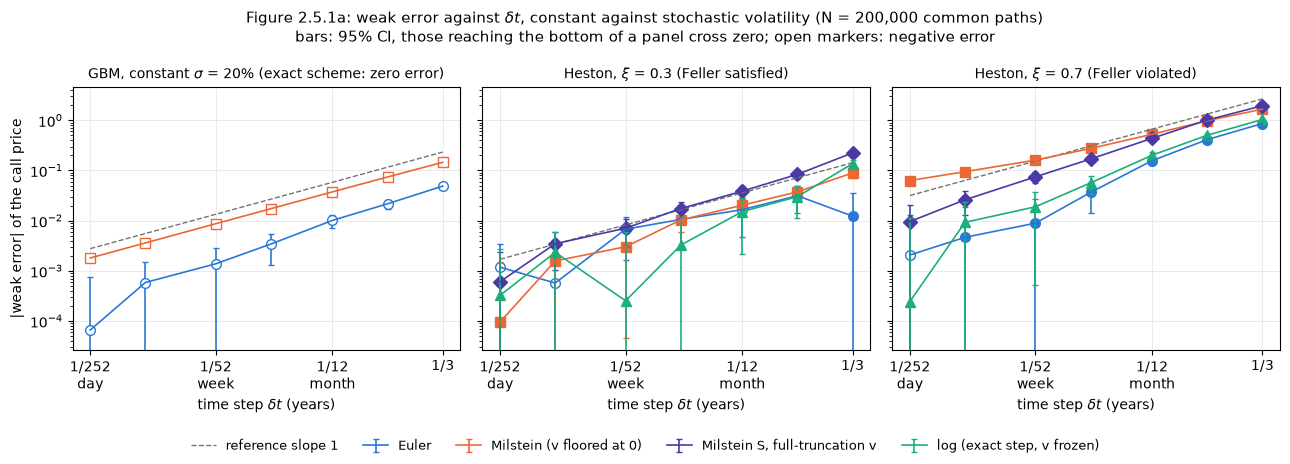

In [15]:
# Figure 2.5.1a: weak error against the step size, constant volatility beside the two Heston sets
sv_colours = {'euler': '#2a78d6', 'milstein': '#eb6834', 'milstein_ft': '#4a3aa7', 'exact': '#1baf7a', 'log': '#1baf7a'}
sv_markers = {'euler': 'o', 'milstein': 's', 'milstein_ft': 'D', 'exact': '^', 'log': '^'}
sv_names = {'euler': 'Euler', 'milstein': 'Milstein (v floored at 0)', 'milstein_ft': 'Milstein S, full-truncation v',
            'exact': 'exact', 'log': 'log (exact step, v frozen)'}
sv_titles = {'GBM': 'GBM, constant $\\sigma$ = 20% (exact scheme: zero error)',
             'Feller satisfied': 'Heston, $\\xi$ = 0.3 (Feller satisfied)',
             'Feller violated': 'Heston, $\\xi$ = 0.7 (Feller violated)'}


def sv_convergence_panel(ax, model, column, slopes):
    # One panel: |error| against dt on log-log axes for each scheme of one model, with 95% error bars.
    # Filled markers: positive error; open markers: negative error. slopes: (order, scheme, style) reference
    # lines, each starting 1.6 times above that scheme's error at the largest step.
    e = sv_errors.xs(model, level='model')
    for scheme in e.index.unique(level='scheme'):
        es = e.xs(scheme, level='scheme')
        if es[column].abs().max() < 1e-12:                          # GBM exact: zero error, nothing to draw
            continue
        size = es[column].abs()
        ax.errorbar(es['dt'], size, yerr=1.96 * es[column + '_se'], color=sv_colours[scheme], lw=1.2,
                    capsize=2, label=sv_names[scheme])
        positive = es[column] > 0
        ax.plot(es['dt'][positive], size[positive], sv_markers[scheme], color=sv_colours[scheme], ms=7)
        ax.plot(es['dt'][~positive], size[~positive], sv_markers[scheme], mfc='white', color=sv_colours[scheme], ms=7)
    dt_line = np.array([1 / 252, 1 / 3])
    for order, scheme, style in slopes:                             # reference line: error proportional to dt^order
        start = 1.6 * e.xs(scheme, level='scheme')[column].abs().iloc[0]
        ax.plot(dt_line, start * (dt_line / dt_line[1])**order, style, color='0.45', lw=1,
                label=f'reference slope {order:g}')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xticks([1 / 252, 1 / 52, 1 / 12, 1 / 3], ['1/252\nday', '1/52\nweek', '1/12\nmonth', '1/3'])
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel(r'time step $\delta t$ (years)')
    ax.grid(True, which='major', color='0.9', lw=0.6)


sv_fig, sv_axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
for sv_ax, sv_model in zip(sv_axes, sv_titles):
    sv_convergence_panel(sv_ax, sv_model, 'weak', slopes=[(1, 'milstein', '--')])
    sv_ax.set_title(sv_titles[sv_model], fontsize=10)
sv_axes[0].set_ylabel('|weak error| of the call price')
sv_fig.legend(*sv_axes[1].get_legend_handles_labels(), loc='lower center', ncol=5, fontsize=9, frameon=False)
sv_fig.suptitle('Figure 2.5.1a: weak error against $\\delta t$, constant against stochastic volatility '
                '(N = 200,000 common paths)\nbars: 95% CI, those reaching the bottom of a panel cross zero; open markers: negative error',
                fontsize=11)
sv_fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()


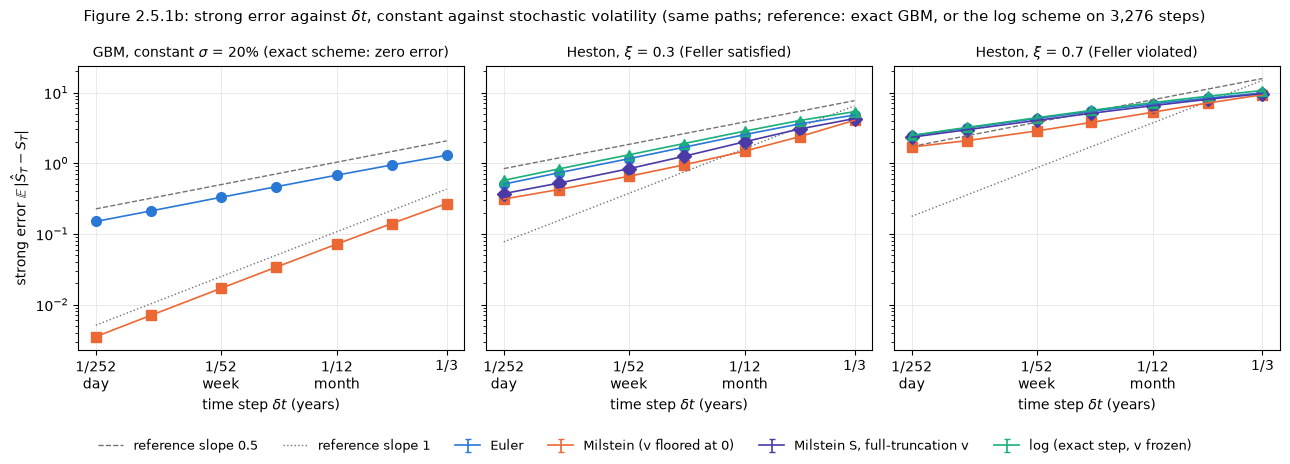

In [16]:
# Figure 2.5.1b: strong error against the step size, same layout as Figure 2.5.1a
sv_fig, sv_axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
for sv_ax, sv_model in zip(sv_axes, sv_titles):
    sv_convergence_panel(sv_ax, sv_model, 'strong', slopes=[(0.5, 'euler', '--'), (1, 'milstein', ':')])
    sv_ax.set_title(sv_titles[sv_model], fontsize=10)
sv_axes[0].set_ylabel(r'strong error $\mathbb{E}\,|\hat S_T - S_T|$')
sv_fig.legend(*sv_axes[1].get_legend_handles_labels(), loc='lower center', ncol=6, fontsize=9, frameon=False)
sv_fig.suptitle('Figure 2.5.1b: strong error against $\\delta t$, constant against stochastic volatility '
                '(same paths; reference: exact GBM, or the log scheme on 3,276 steps)', fontsize=11)
sv_fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()


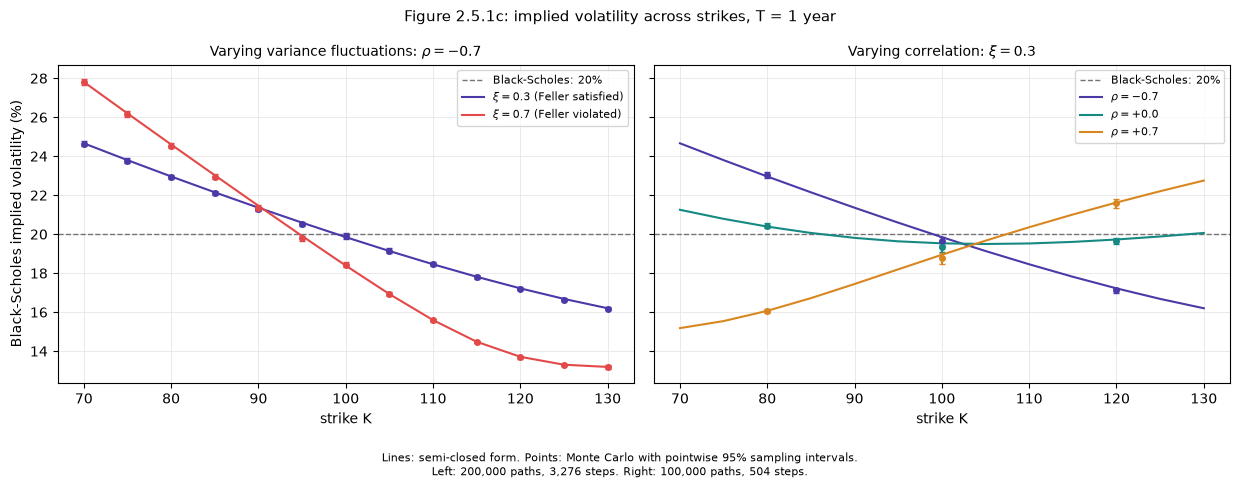

In [17]:
from scipy.optimize import brentq


def sv_implied_vol(price, strike, kind):
    # Black-Scholes implied volatility (Lecture 7, p.9): the sigma at which bs_price returns the given price.
    return brentq(lambda s: bs_price(S0, strike, T, r, s, kind) - price, 1e-4, 2.0)


# Implied volatility across strikes: semi-closed form (lines) and the fine-step Monte Carlo paths (points, 95% CI).
# Each strike uses its out-of-the-money option (put below S0, call at and above), whose price is most precise.
sv_strikes = np.arange(70, 131, 5)
sv_smile_rows = []
for sv_name, sv_p in sv_params.items():
    for sv_K in sv_strikes:
        sv_kind = 'put' if sv_K < S0 else 'call'
        sv_Y = np.exp(-r * T) * payoff(sv_S_T_ref[sv_name], sv_K, sv_kind)
        sv_mean, sv_se = sv_Y.mean(), sv_Y.std(ddof=1) / np.sqrt(sv_Y.size)
        sv_smile_rows.append(dict(model=sv_name, strike=sv_K,
                                  semi_closed=sv_implied_vol(heston_price(S0, sv_K, T, r, sv_p, sv_kind), sv_K, sv_kind),
                                  mc=sv_implied_vol(sv_mean, sv_K, sv_kind),
                                  mc_low=sv_implied_vol(sv_mean - 1.96 * sv_se, sv_K, sv_kind),
                                  mc_high=sv_implied_vol(sv_mean + 1.96 * sv_se, sv_K, sv_kind)))
sv_smile = pd.DataFrame(sv_smile_rows)

# A second input change: correlation, with xi = 0.3 and all other inputs fixed.
# Reuse the same draws across rho and pair 252/504-step paths to check time-step sensitivity.
sv_rhos = (-0.7, 0.0, 0.7)
sv_rho_n_paths, sv_rho_n_steps, sv_rho_batch = 100_000, 504, 4000
sv_rho_rng = np.random.default_rng(SEED + 252)
sv_rho_terminal = {rho: [] for rho in sv_rhos}
sv_rho_coarse = {rho: [] for rho in sv_rhos}
for sv_start in range(0, sv_rho_n_paths, sv_rho_batch):
    sv_ZS = sv_rho_rng.standard_normal((sv_rho_batch, sv_rho_n_steps))
    sv_Zv = sv_rho_rng.standard_normal((sv_rho_batch, sv_rho_n_steps))
    sv_ZS_coarse = sv_ZS.reshape(sv_rho_batch, 252, 2).sum(axis=2) / np.sqrt(2)
    sv_Zv_coarse = sv_Zv.reshape(sv_rho_batch, 252, 2).sum(axis=2) / np.sqrt(2)
    for sv_rho in sv_rhos:
        sv_p = dict(sv_params['Feller satisfied'], rho=sv_rho)
        sv_rho_terminal[sv_rho].append(heston_terminal(S0, r, T, sv_p, sv_ZS, sv_Zv, 'log')[0])
        sv_rho_coarse[sv_rho].append(heston_terminal(S0, r, T, sv_p, sv_ZS_coarse, sv_Zv_coarse, 'log')[0])
sv_rho_terminal = {rho: np.concatenate(parts) for rho, parts in sv_rho_terminal.items()}
sv_rho_coarse = {rho: np.concatenate(parts) for rho, parts in sv_rho_coarse.items()}

sv_rho_rows, sv_rho_checks = [], []
for sv_rho in sv_rhos:
    sv_p = dict(sv_params['Feller satisfied'], rho=sv_rho)
    for sv_K in sv_strikes:
        sv_kind = 'put' if sv_K < S0 else 'call'
        sv_price = heston_price(S0, sv_K, T, r, sv_p, sv_kind)
        sv_row = dict(rho=sv_rho, strike=sv_K, semi_closed=sv_implied_vol(sv_price, sv_K, sv_kind))
        if sv_K in (80, 100, 120):
            sv_Y = np.exp(-r * T) * payoff(sv_rho_terminal[sv_rho], sv_K, sv_kind)
            sv_mean, sv_se = sv_Y.mean(), sv_Y.std(ddof=1) / np.sqrt(sv_Y.size)
            sv_row.update(mc=sv_implied_vol(sv_mean, sv_K, sv_kind),
                          mc_low=sv_implied_vol(sv_mean - 1.96 * sv_se, sv_K, sv_kind),
                          mc_high=sv_implied_vol(sv_mean + 1.96 * sv_se, sv_K, sv_kind))
            sv_difference = sv_Y - np.exp(-r * T) * payoff(sv_rho_coarse[sv_rho], sv_K, sv_kind)
            sv_rho_checks.append(dict(rho=sv_rho, strike=sv_K, price=sv_mean, benchmark=sv_price,
                                     SE=sv_se, paired_change=sv_difference.mean(),
                                     paired_SE=sv_difference.std(ddof=1) / np.sqrt(sv_Y.size)))
        sv_rho_rows.append(sv_row)
sv_rho_smile = pd.DataFrame(sv_rho_rows)
sv_rho_check = pd.DataFrame(sv_rho_checks)  # retained for inspection, not another results table

sv_fig, sv_axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
for sv_ax in sv_axes:
    sv_ax.axhline(100 * sigma, color='0.45', ls='--', lw=1, label='Black-Scholes: 20%')
    sv_ax.set_xlabel('strike K')
    sv_ax.grid(True, color='0.9', lw=0.6)
sv_axes[0].set_ylabel('Black-Scholes implied volatility (%)')
for (sv_name, sv_g), sv_colour in zip(sv_smile.groupby('model', sort=False), ['#4a3aa7', '#e34948']):
    sv_xi = sv_params[sv_name]['xi']
    sv_axes[0].plot(sv_g['strike'], 100 * sv_g['semi_closed'], color=sv_colour, lw=1.5,
                    label=rf'$\xi={sv_xi}$ ({sv_name})')
    sv_axes[0].errorbar(sv_g['strike'], 100 * sv_g['mc'],
                       yerr=[100 * (sv_g['mc'] - sv_g['mc_low']), 100 * (sv_g['mc_high'] - sv_g['mc'])],
                       fmt='o', ms=4, color=sv_colour, capsize=2)
for (sv_rho, sv_g), sv_colour in zip(sv_rho_smile.groupby('rho', sort=False), ['#4a3aa7', '#168a82', '#d88720']):
    sv_axes[1].plot(sv_g['strike'], 100 * sv_g['semi_closed'], color=sv_colour, lw=1.5,
                    label=rf'$\rho={sv_rho:+.1f}$')
    sv_mc = sv_g.dropna(subset=['mc'])
    sv_axes[1].errorbar(sv_mc['strike'], 100 * sv_mc['mc'],
                       yerr=[100 * (sv_mc['mc'] - sv_mc['mc_low']), 100 * (sv_mc['mc_high'] - sv_mc['mc'])],
                       fmt='o', ms=4, color=sv_colour, capsize=2)
sv_axes[0].set_title(r'Varying variance fluctuations: $\rho=-0.7$', fontsize=10)
sv_axes[1].set_title(r'Varying correlation: $\xi=0.3$', fontsize=10)
for sv_ax in sv_axes:
    sv_ax.legend(fontsize=8, loc='upper right')
sv_fig.suptitle('Figure 2.5.1c: implied volatility across strikes, T = 1 year', fontsize=11)
sv_fig.text(0.5, 0.01, 'Lines: semi-closed form. Points: Monte Carlo with pointwise 95% sampling intervals.\n'
            'Left: 200,000 paths, 3,276 steps. Right: 100,000 paths, 504 steps.',
            ha='center', fontsize=8)
sv_fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


**Reading the results.** The independent pricing checks agree closely (Table 2.5.1a).
With $\xi=0.3$ (“Feller satisfied”), the implemented Milstein approximation retains a smaller terminal-path
error than Euler, but much less of the advantage observed under GBM. Its fitted order is 0.57 relative to
the fine-grid reference (Table 2.5.1c).

With $\xi=0.7$ (“Feller violated”), the variance treatment becomes more consequential. At daily steps,
the floored Milstein call-price difference from the reference is +0.0630; the Milstein-FT variant gives
+0.0096 and is not resolved from zero at the 95% level (Table 2.5.1b). These implementations also differ in
their variance update, so the comparison does not isolate flooring alone. Euler's numerical variance is
negative on 10.01% of daily steps in this case.

Figure 2.5.1c shows the change in the pricing distribution. In the left panel, implied volatility is no longer
flat across strikes; for the higher $\xi$ it falls from about 27.8% at $K=70$ to 13.2% at $K=130$. Matching
the mean variance of the Black–Scholes benchmark does not reproduce its option prices.

The right panel changes only correlation. The downward slope at $\rho=-0.7$ becomes much flatter at zero
correlation and slopes upwards at $\rho=+0.7$. This helped me separate the effect of random variance from
the effect of linking variance and stock shocks: the original downward slope depended on both choices.
The largest of the nine Monte Carlo price discrepancies is 2.11 standard errors from the benchmark,
slightly outside its pointwise 95% interval. The paired change from 252 to 504 steps, allowing for its
own sampling uncertainty, is below 0.13 of a pricing standard error at every checked point. This supports
using the curves to interpret correlation here, without treating the simulation as exact.
